<a href="https://colab.research.google.com/github/nandesh2k25/IK-DNN/blob/master/IK_MDN(3R%20in%203D)_tuned/notebooks/august_thesis_claude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

# Thesis Model — Built From Scratch (NumPy, Manual Backprop)

This notebook rebuilds the core of the thesis model (3R robot arm inverse kinematics) as a **plain feedforward neural network implemented from scratch**, in the style of Andrew Ng's Deep Learning Specialization (Course 1/2 assignments):

- No PyTorch, no autograd — every gradient is derived and coded by hand.
- No mixture density network yet — a single deterministic output head, trained with MSE. The target is `[sin(theta1), cos(theta1), theta2, theta3]` (`theta1` is sin/cos-encoded to remove its +-180 degree wraparound discontinuity; `theta2`/`theta3` stay as raw radians since they never wrap).
- Input is `[x, y, z, elbow_config]` (v3) — `elbow_config` is a known, oracle input at training time that resolves the theta2/theta3 elbow-branch ambiguity (see Section 1). At inference the caller only supplies `(x,y,z)`; `predict_ik` (Section 4) queries both elbow configurations and picks whichever reprojects closer via forward kinematics.
- **v5**: mini-batch gradient descent (Section 3.6) — `nn_model` takes a gradient step per mini-batch instead of per full pass over the data, converging in far fewer epochs than full-batch GD needed iterations.
- **v6**: Adam (Section 3.7) — momentum and RMSprop with bias correction, still hand-derived. Selected via `optimizer="adam"`; plain GD remains the default so v0–v5 stay reproducible. Its learning rate is on a different scale from plain GD's, so Section 4.2 sweeps it rather than reusing v5's. Still no mixture output head, and no learning-rate decay yet.

**Structure:**
1. Data Generation — sample joint angles, compute forward kinematics, build the `(position -> angles)` dataset.
2. Helper / Utility Functions — activations and their derivatives, error-metric helpers.
3. Neural Network Model — parameter initialization, forward propagation, cost computation, backward propagation, parameter updates, mini-batching, Adam, and the full training loop.
4. Analysis — train the model, inspect the cost curve, evaluate prediction accuracy, and sweep the optimizer's learning rate.
5. Diagnostics — prediction scatter per joint, and singularity-proximity stratification.

## 1. Data Generation

The robot is a 3R arm: a base yaw joint `theta1`, plus a 2-link planar arm (`theta2`, `theta3`) that moves in the `(r, z)` plane swept out by that yaw.

```
r = L1 + L2*cos(theta2) + L3*cos(theta2 + theta3)
z = L2*sin(theta2) + L3*sin(theta2 + theta3)
x = r*cos(theta1)
y = r*sin(theta1)
```

We sample joint angles uniformly within their limits, compute the resulting end-effector position via forward kinematics, and treat `(x, y, z) -> (theta1, theta2, theta3)` as the supervised regression problem. Inputs and targets are both standardized (zero mean, unit variance) using train-set statistics only.

### Angle Encoding: sin/cos for theta1

`theta1` ranges over the full circle (-180°, 180°]. Two physically near-identical directions right at the wrap boundary — e.g. 179° and -179° — are numerically far apart as raw radians. A network regressing raw `theta1` is forced to fit a discontinuous function right at that boundary, which shows up as large error there (see `QUESTIONS.md`, Q1).

Fix: don't regress `theta1` directly. Regress `[sin(theta1), cos(theta1)]` instead — a continuous, wraparound-free representation — and recover the angle afterwards with `atan2(sin, cos)`, which is exact and lossless. `theta2`/`theta3` stay as raw radians since they're limited to (-90°, 90°) and never wrap.

The network's target now has **4 components**: `[sin(theta1), cos(theta1), theta2, theta3]`.

### Elbow Configuration Input (v3): removing the theta2/theta3 branch ambiguity

For a given `(x, y, z)`, there are generally **two** valid `(theta2, theta3)` solutions — "elbow up" and "elbow down" — that reach the exact same position (the planar 2-link sub-chain is a classic 2-to-1 inverse map). A single deterministic network fed only `(x, y, z)` cannot represent this: wherever the two branches are close together in input space, its MSE-optimal prediction is the *average* of both branches, which is generally not a valid solution at all. This is the dominant reason `theta3`'s error has stayed large across v1/v2 above.

**Fix (v3):** tell the network which branch to solve for. Add a 4th input, `elbow_config`, derived exactly from the already-known `theta3` at data-generation time:

$$
\text{elbow\_config} = \begin{cases} +1 & \theta_3 \geq 0 \\ -1 & \theta_3 < 0 \end{cases}
$$

With `elbow_config` known, the mapping `(x, y, z, elbow_config) -> (theta1, theta2, theta3)` is single-valued — no more averaging conflicting branches. `elbow_config` is left un-normalized (like `sin`/`cos` earlier), since ±1 is already a clean, bounded, symmetric value.

**But the caller of the trained model only has `(x, y, z)`** — they don't know the branch in advance. So at inference, `predict_ik` queries the network with *both* `elbow_config = +1` and `elbow_config = -1`, decodes both candidate angle triples, runs each through forward kinematics, and returns whichever one's reprojected position is closer to the requested `(x, y, z)`. The network never has to guess the branch; the branch choice is resolved by checking which one is physically consistent.

(Flagged for future reference, not implemented: an alternative would be to use the branch label only as a *training-time* signal for a 2-head architecture that still takes just `(x,y,z)` as input — see `thesis_doc.md`, §6.6.)

In [3]:
## ---- Robot parameters ----
L1, L2, L3 = 1.0, 1.0, 0.5
THETA1_LIM = (-np.pi, np.pi)
THETA2_LIM = (-np.pi / 2, np.pi / 2)
THETA3_LIM = (-np.pi / 2, np.pi / 2)


def forward_kinematics(theta1, theta2, theta3, L1=L1, L2=L2, L3=L3):
    """Vectorized FK: joint angles (1D arrays) -> end-effector position (x, y, z)."""
    r = L1 + L2 * np.cos(theta2) + L3 * np.cos(theta2 + theta3)
    z = L2 * np.sin(theta2) + L3 * np.sin(theta2 + theta3)
    x = r * np.cos(theta1)
    y = r * np.sin(theta1)
    return x, y, z


## ---- theta1 sin/cos encoding (removes the +-180 deg wraparound discontinuity) ----
def encode_theta1_sincos(Y_theta):
    """Y_theta: (3, m) raw [theta1, theta2, theta3] -> (4, m) [sin1, cos1, theta2, theta3]."""
    theta1, theta2, theta3 = Y_theta[0], Y_theta[1], Y_theta[2]
    return np.vstack([np.sin(theta1), np.cos(theta1), theta2, theta3])


def decode_theta1_sincos(Y_enc):
    """Y_enc: (4, m) [sin1, cos1, theta2, theta3] -> (3, m) raw [theta1, theta2, theta3].

    atan2 recovers theta1 exactly regardless of the magnitude of sin1/cos1,
    so this is robust even if the network's raw predictions don't exactly
    satisfy sin^2 + cos^2 = 1.
    """
    sin1, cos1, theta2, theta3 = Y_enc[0], Y_enc[1], Y_enc[2], Y_enc[3]
    theta1 = np.arctan2(sin1, cos1)
    return np.vstack([theta1, theta2, theta3])


## ---- elbow configuration (removes the theta2/theta3 branch ambiguity) ----
def encode_elbow_config(Y_theta_raw):
    """Y_theta_raw: (3, m) raw [theta1, theta2, theta3] -> (1, m) elbow_config in {+1, -1}.

    +1 if theta3 >= 0 (one branch), -1 if theta3 < 0 (the other branch).
    Exact and free, since theta3 is already known at data-generation time.
    """
    theta3 = Y_theta_raw[2]
    return np.where(theta3 >= 0.0, 1.0, -1.0)[None, :]


def generate_dataset(n_samples, seed=0):
    """Sample random joint configurations and return (X, Y) with examples as columns.

    X: (3, n_samples) end-effector positions [x, y, z]
    Y: (3, n_samples) RAW joint angles [theta1, theta2, theta3] (encoded later)
    """
    rng = np.random.default_rng(seed)
    theta1 = rng.uniform(*THETA1_LIM, n_samples)
    theta2 = rng.uniform(*THETA2_LIM, n_samples)
    theta3 = rng.uniform(*THETA3_LIM, n_samples)

    x, y, z = forward_kinematics(theta1, theta2, theta3)

    X = np.vstack([x, y, z])
    Y = np.vstack([theta1, theta2, theta3])
    return X, Y


# ---- Generate + split (raw angles, raw xyz -- no elbow_config yet) ----
N_SAMPLES = 30000
X_all_xyz, Y_all_raw = generate_dataset(N_SAMPLES, seed=0)

n_train = int(0.8 * N_SAMPLES)
n_dev = int(0.1 * N_SAMPLES)

X_train_xyz, Y_train_raw = X_all_xyz[:, :n_train], Y_all_raw[:, :n_train]
X_dev_xyz, Y_dev_raw = X_all_xyz[:, n_train:n_train + n_dev], Y_all_raw[:, n_train:n_train + n_dev]
X_test_xyz, Y_test_raw = X_all_xyz[:, n_train + n_dev:], Y_all_raw[:, n_train + n_dev:]

print(f"train: {X_train_xyz.shape[1]}  dev: {X_dev_xyz.shape[1]}  test: {X_test_xyz.shape[1]}")

# ---- Encode targets: theta1 -> (sin, cos); theta2, theta3 stay raw ----
Y_train = encode_theta1_sincos(Y_train_raw)
Y_dev = encode_theta1_sincos(Y_dev_raw)
Y_test = encode_theta1_sincos(Y_test_raw)

# ---- Build TRAINING inputs: append the oracle elbow_config to raw (x,y,z) ----
# NOTE: X_train/X_dev/X_test (4, m) are for TRAINING only -- they include the
# ground-truth elbow_config, which is not available at inference. Inference
# uses X_*_xyz (3, m) directly via predict_ik (Section 4), which queries both
# elbow_config values itself.
X_train = np.vstack([X_train_xyz, encode_elbow_config(Y_train_raw)])
X_dev = np.vstack([X_dev_xyz, encode_elbow_config(Y_dev_raw)])
X_test = np.vstack([X_test_xyz, encode_elbow_config(Y_test_raw)])

# ---- Standardize using train-set statistics only ----
# sin1/cos1 (Y rows 0-1) and elbow_config (X row 3) are already in [-1, 1]
# with mean ~0 -- leave them un-normalized (identity mean=0, std=1) so
# decoding never has to undo a normalization before atan2, and elbow_config
# stays exactly +-1. theta2/theta3 (Y rows 2-3) and x,y,z (X rows 0-2) still
# get standard z-score normalization.
xyz_mean, xyz_std = X_train_xyz.mean(axis=1, keepdims=True), X_train_xyz.std(axis=1, keepdims=True)
X_mean = np.vstack([xyz_mean, np.zeros((1, 1))])
X_std = np.vstack([xyz_std, np.ones((1, 1))])

theta23_mean = Y_train[2:4].mean(axis=1, keepdims=True)
theta23_std = Y_train[2:4].std(axis=1, keepdims=True)
Y_mean = np.vstack([np.zeros((2, 1)), theta23_mean])
Y_std = np.vstack([np.ones((2, 1)), theta23_std])


def normalize(A, mean, std):
    return (A - mean) / std


def denormalize(A_norm, mean, std):
    return A_norm * std + mean


X_train_norm, Y_train_norm = normalize(X_train, X_mean, X_std), normalize(Y_train, Y_mean, Y_std)
X_dev_norm, Y_dev_norm = normalize(X_dev, X_mean, X_std), normalize(Y_dev, Y_mean, Y_std)
X_test_norm, Y_test_norm = normalize(X_test, X_mean, X_std), normalize(Y_test, Y_mean, Y_std)

print("X_train_norm mean/std:", X_train_norm.mean(axis=1).round(3), X_train_norm.std(axis=1).round(3))
print("Y_train_norm mean/std:", Y_train_norm.mean(axis=1).round(3), Y_train_norm.std(axis=1).round(3))

train: 24000  dev: 3000  test: 3000
X_train_norm mean/std: [-0.     0.     0.    -0.008] [1. 1. 1. 1.]
Y_train_norm mean/std: [ 0.008  0.009 -0.    -0.   ] [0.705 0.709 1.    1.   ]


## 2. Helper / Utility Functions

Reusable pieces that aren't themselves one of the five core NN steps: activation functions with their derivatives (needed by forward and backward propagation), and error-metric helpers used later in the analysis section.

In [4]:
## ---- Activation functions (forward) ----
def relu(Z):
    return np.maximum(0, Z)


def linear(Z):
    return Z


## ---- Activation derivatives (backward): dZ = dA * activation'(Z) ----
def relu_backward(dA, Z):
    dZ = np.array(dA, copy=True)
    dZ[Z <= 0] = 0
    return dZ


def linear_backward(dA, Z):
    return np.array(dA, copy=True)


## ---- Error-metric helpers (used in Section 4) ----
def mae_degrees(pred_theta, true_theta):
    """Mean absolute *circular* error per joint, in degrees. Inputs shape (3, m), radians.

    Uses the shortest angular distance rather than a plain difference: raw
    angle values wrap at +-180 degrees (relevant to theta1). Without this, a
    perfectly good prediction near the wrap boundary (true=179 deg,
    pred=-179 deg) would be scored as a ~358 degree error instead of the
    true ~2 degrees.
    """
    diff = pred_theta - true_theta
    diff = (diff + np.pi) % (2 * np.pi) - np.pi  # wrap to (-pi, pi]
    return np.mean(np.abs(diff), axis=1) * (180.0 / np.pi)


def pose_error_mm(pred_theta, true_xyz, meters_to_mm=1000.0):
    """Euclidean end-effector error (mm) between FK(predicted angles) and the true target position."""
    x_pred, y_pred, z_pred = forward_kinematics(pred_theta[0], pred_theta[1], pred_theta[2])
    pred_xyz = np.vstack([x_pred, y_pred, z_pred])
    return np.linalg.norm(pred_xyz - true_xyz, axis=0) * meters_to_mm

## 3. Neural Network Model

A plain fully-connected network: ReLU hidden layers, a linear (identity) output layer, trained with mean-squared error and plain batch gradient descent. Every step below is written out explicitly rather than relying on a framework — this is the baseline to verify correctness before adding optimizers or a mixture output head.

### 3.1 Parameter Initialization

Weights use He initialization (`* sqrt(2 / n_prev)`), appropriate for ReLU hidden layers; biases start at zero.

In [5]:
def initialize_parameters(layer_dims, seed=1):
    """layer_dims: list like [n_x, n_h1, n_h2, ..., n_y]. Returns dict of W1,b1,...,WL,bL."""
    rng = np.random.default_rng(seed)
    parameters = {}
    L = len(layer_dims)

    for l in range(1, L):
        parameters[f"W{l}"] = rng.standard_normal((layer_dims[l], layer_dims[l - 1])) * np.sqrt(2.0 / layer_dims[l - 1])
        parameters[f"b{l}"] = np.zeros((layer_dims[l], 1))

    return parameters


# sanity check (input dim = 4: x,y,z,elbow_config; output dim = 4, matching the sin/cos-encoded target)
_p = initialize_parameters([4, 5, 4, 4])
for k, v in _p.items():
    print(k, v.shape)

W1 (5, 4)
b1 (5, 1)
W2 (4, 5)
b2 (4, 1)
W3 (4, 4)
b3 (4, 1)


### 3.2 Forward Propagation

Each layer computes `Z = W . A_prev + b` then applies its activation (ReLU for hidden layers, linear for the output layer). Every layer's `(A_prev, W, b, Z)` is cached — backward propagation needs all of it.

In [6]:
def linear_activation_forward(A_prev, W, b, activation):
    Z = W.dot(A_prev) + b

    if activation == "relu":
        A = relu(Z)
    elif activation == "linear":
        A = linear(Z)
    else:
        raise ValueError(f"Unknown activation: {activation}")

    cache = (A_prev, W, b, Z)
    return A, cache


def forward_propagation(X, parameters):
    """Runs the full network: ReLU on every hidden layer, linear on the output layer.

    Returns AL (network output, shape (n_y, m)) and the list of per-layer caches.
    """
    caches = []
    A = X
    L = len(parameters) // 2

    for l in range(1, L):
        A_prev = A
        A, cache = linear_activation_forward(A_prev, parameters[f"W{l}"], parameters[f"b{l}"], activation="relu")
        caches.append(cache)

    AL, cache = linear_activation_forward(A, parameters[f"W{L}"], parameters[f"b{L}"], activation="linear")
    caches.append(cache)

    return AL, caches


# sanity check
_AL, _caches = forward_propagation(X_train_norm[:, :5], _p)
print("AL shape:", _AL.shape, " num caches:", len(_caches))

AL shape: (4, 5)  num caches: 3


### 3.3 Cost Computation

Mean squared error, averaged over both examples and output dimensions:

```
J = (1 / 2m) * sum((AL - Y)^2)
```

The `1/2` is a convenience so the gradient `dJ/dAL = (AL - Y) / m` comes out clean.

In [7]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = (1.0 / (2 * m)) * np.sum((AL - Y) ** 2)
    return float(np.squeeze(cost))


# sanity check
print("cost:", compute_cost(_AL, Y_train_norm[:, :5]))

cost: 1.3349549303095767


### 3.4 Backward Propagation

Starting from `dAL = AL - Y` (the derivative of the *sum* term; the `1/m` averaging is applied once, inside the `dW`/`db` formulas below — not here, to avoid double-counting it at every layer), propagate gradients backward layer by layer using the cached `(A_prev, W, b, Z)` from the forward pass:

```
dZ = dA * activation'(Z)
dW = (1/m) * dZ . A_prev^T
db = (1/m) * sum(dZ, axis=1)
dA_prev = W^T . dZ
```

In [8]:
def linear_activation_backward(dA, cache, activation):
    A_prev, W, b, Z = cache
    m = A_prev.shape[1]

    if activation == "relu":
        dZ = relu_backward(dA, Z)
    elif activation == "linear":
        dZ = linear_backward(dA, Z)
    else:
        raise ValueError(f"Unknown activation: {activation}")

    dW = (1.0 / m) * dZ.dot(A_prev.T)
    db = (1.0 / m) * np.sum(dZ, axis=1, keepdims=True)
    dA_prev = W.T.dot(dZ)

    return dA_prev, dW, db


def backward_propagation(AL, Y, caches):
    """Returns a dict of gradients: dW1,db1,...,dWL,dbL (plus intermediate dA's)."""
    grads = {}
    L = len(caches)

    # NOTE: no /m here — the 1/m averaging happens exactly once, inside
    # linear_activation_backward's dW/db computation. Dividing here too would
    # double-count it at every layer during backprop.
    dAL = AL - Y

    current_cache = caches[L - 1]
    dA_prev, dW, db = linear_activation_backward(dAL, current_cache, activation="linear")
    grads[f"dW{L}"] = dW
    grads[f"db{L}"] = db
    grads[f"dA{L - 1}"] = dA_prev

    for l in reversed(range(1, L)):
        current_cache = caches[l - 1]
        dA_prev, dW, db = linear_activation_backward(grads[f"dA{l}"], current_cache, activation="relu")
        grads[f"dW{l}"] = dW
        grads[f"db{l}"] = db
        grads[f"dA{l - 1}"] = dA_prev

    return grads


# sanity check
_grads = backward_propagation(_AL, Y_train_norm[:, :5], _caches)
for k in sorted(_grads.keys()):
    print(k, _grads[k].shape)

dA0 (4, 5)
dA1 (5, 5)
dA2 (4, 5)
dW1 (5, 4)
dW2 (4, 5)
dW3 (4, 4)
db1 (5, 1)
db2 (4, 1)
db3 (4, 1)


### 3.5 Update Parameters

Plain gradient descent:

```
W := W - learning_rate * dW
b := b - learning_rate * db
```

The same step size for every parameter, straight down the current gradient — no memory of previous steps. Section 3.7 adds Adam on top of this; this function stays unchanged and remains the default (`optimizer="gd"`), so every result from v0 through v5 stays reproducible.

In [9]:
def update_parameters(parameters, grads, learning_rate):
    L = len(parameters) // 2

    for l in range(1, L + 1):
        parameters[f"W{l}"] = parameters[f"W{l}"] - learning_rate * grads[f"dW{l}"]
        parameters[f"b{l}"] = parameters[f"b{l}"] - learning_rate * grads[f"db{l}"]

    return parameters

### 3.6 Mini-Batch Gradient Descent

Full-batch gradient descent (Section 3.5) takes one parameter update per pass over the *entire* training set — for 24,000 examples through a `[4, 256, 128, 64, 4]` network, each update is a large matmul over all of them, and reaching a good cost this way means many such updates (slow).

Mini-batch gradient descent splits each pass ("epoch") into small batches instead, taking one gradient step per batch. That's many more updates per epoch (24000/256 ≈ 94 updates for a batch size of 256, vs. 1 for full-batch), which typically reaches a given cost in far fewer epochs — this is the main lever for training faster. It does **not** reduce the total arithmetic per epoch (an epoch of mini-batches still touches all 24,000 examples); the speedup comes from needing fewer epochs, not less work per epoch.

`random_mini_batches` below shuffles the training examples and splits them into batches, mirroring the same helper from Andrew Ng's Course 2 mini-batch assignment. `forward_propagation`, `backward_propagation`, `compute_cost`, and `update_parameters` are all unchanged — they already work on whatever batch they're handed.

In [10]:
def random_mini_batches(X, Y, batch_size, seed=0):
    """Shuffles (X, Y) together (by column) and splits into mini-batches of batch_size.

    Returns a list of (mini_batch_X, mini_batch_Y) tuples. The last batch may
    be smaller than batch_size if m is not an exact multiple.
    """
    rng = np.random.default_rng(seed)
    m = X.shape[1]
    permutation = rng.permutation(m)
    X_shuffled = X[:, permutation]
    Y_shuffled = Y[:, permutation]

    mini_batches = []
    num_complete_batches = m // batch_size
    for k in range(num_complete_batches):
        mb_X = X_shuffled[:, k * batch_size:(k + 1) * batch_size]
        mb_Y = Y_shuffled[:, k * batch_size:(k + 1) * batch_size]
        mini_batches.append((mb_X, mb_Y))

    if m % batch_size != 0:
        mb_X = X_shuffled[:, num_complete_batches * batch_size:]
        mb_Y = Y_shuffled[:, num_complete_batches * batch_size:]
        mini_batches.append((mb_X, mb_Y))

    return mini_batches


# sanity check: batches partition the data with no overlap/omission
_mbs = random_mini_batches(X_train_norm, Y_train_norm, batch_size=256, seed=0)
_sizes = [mb[0].shape[1] for mb in _mbs]
print(f"num batches: {len(_mbs)}  batch sizes: {_sizes[:3]} ... {_sizes[-1]}  sum: {sum(_sizes)}  (should equal {X_train_norm.shape[1]})")

num batches: 94  batch sizes: [256, 256, 256] ... 192  sum: 24000  (should equal 24000)


### 3.7 Adam Optimizer

Plain gradient descent (Section 3.5) takes the same-sized step for every parameter, in exactly the direction of the current gradient. Adam improves on both halves of that. It is not a new idea so much as **two older ideas fused together**, which is why implementing Adam necessarily means implementing both:

**Momentum** — accumulate an exponentially-weighted average of the gradient, `v`, and step along *that* instead of the raw gradient. Mini-batch gradients are noisy; averaging them cancels the noise that flips sign batch-to-batch while reinforcing the consistent direction.

$$v = \beta_1 v + (1-\beta_1)\, dW$$

**RMSprop** — accumulate an exponentially-weighted average of the *squared* gradient, `s`, and divide the step by its square root. This normalizes each parameter's step by how large that parameter's own gradients have recently been, so parameters with small gradients still move meaningfully and ones with large gradients don't overshoot.

$$s = \beta_2 s + (1-\beta_2)\, dW^{2}$$

**Bias correction** — both accumulators start at zero, so early on both are biased toward zero: after one step `v` is only `(1-β₁)·dW = 0.1·dW`, and `s` is only `(1-β₂)·dW² = 0.001·dW²`. Dividing each by `1 - βᵗ` exactly undoes this. The factors decay to 1 as `t` grows, so correction only matters for the first few dozen steps.

$$\hat{v} = \frac{v}{1-\beta_1^{\,t}}, \qquad \hat{s} = \frac{s}{1-\beta_2^{\,t}}$$

Note that the two biases do **not** cancel in the ratio `v/√s`. Since `s` is far more biased than `v`, dropping correction entirely makes the first step *too large* by a factor of `(1-β₁)/√(1-β₂) = 0.1/0.0316 ≈ 3.2`, not too small — the opposite of what the individual accumulators being "too small" suggests. The sanity check below asserts the corrected first step is `α`-sized and prints the uncorrected value alongside it.

**The update:**

$$W := W - \alpha \frac{\hat{v}}{\sqrt{\hat{s}} + \epsilon}$$

Defaults `β₁ = 0.9`, `β₂ = 0.999`, `ε = 1e-8`.

> **Two things to be careful about here.**
>
> 1. **`t` counts parameter updates, not epochs.** Bias correction uses `βᵗ`, so passing the epoch index instead of the global update counter leaves the correction wrong by orders of magnitude for the entire run. With batch size 256 over 24,000 examples that's a factor of ~94 per epoch. Like the `dAL` bug in Section 3.4, this trains *smoothly* while being wrong — so it is checked explicitly rather than assumed.
> 2. **The learning rate does not carry over from plain GD.** Because the step is divided by `√ŝ`, it is roughly `±α` per parameter *regardless of gradient magnitude*. v5's `α = 0.05` is enormous by Adam's standards; `1e-3` is the usual starting point. This is why v6 sweeps `α` rather than reusing v5's value.

In [11]:
def initialize_adam(parameters):
    """Zero-initialized moment accumulators for Adam -- one pair per parameter.

    v = 1st moment (momentum: EW average of the gradient)
    s = 2nd moment (RMSprop: EW average of the SQUARED gradient)

    Keys mirror the gradient dict ("dW1", "db1", ...) so they can be indexed
    with the same key as grads. Starting both at zero is what makes bias
    correction necessary -- see update_parameters_with_adam.
    """
    L = len(parameters) // 2
    v, s = {}, {}

    for l in range(1, L + 1):
        for p in (f"W{l}", f"b{l}"):
            v[f"d{p}"] = np.zeros_like(parameters[p])
            s[f"d{p}"] = np.zeros_like(parameters[p])

    return v, s


def update_parameters_with_adam(parameters, grads, v, s, t, learning_rate,
                                beta1=0.9, beta2=0.999, epsilon=1e-8):
    """One Adam update step over all layers.

    t: the GLOBAL update counter (1, 2, 3, ...) -- NOT the epoch number.
       Bias correction uses beta**t, so passing an epoch index would leave the
       correction wrong for the whole run. Must be >= 1: t=0 divides by
       1 - beta**0 = 0.

    v, s: persistent across the whole run -- create them once with
          initialize_adam() and pass the same pair back in every step. They are
          mutated in place and also returned.
    """
    L = len(parameters) // 2

    for l in range(1, L + 1):
        for p in (f"W{l}", f"b{l}"):
            g = grads[f"d{p}"]

            # momentum: which way have gradients been pointing lately?
            v[f"d{p}"] = beta1 * v[f"d{p}"] + (1 - beta1) * g
            # RMSprop: how large have this parameter's gradients been lately?
            s[f"d{p}"] = beta2 * s[f"d{p}"] + (1 - beta2) * g ** 2

            # bias correction -- undoes the zero-init bias; -> 1 as t grows
            v_corrected = v[f"d{p}"] / (1 - beta1 ** t)
            s_corrected = s[f"d{p}"] / (1 - beta2 ** t)

            parameters[p] = parameters[p] - learning_rate * v_corrected / (np.sqrt(s_corrected) + epsilon)

    return parameters, v, s


## ---- sanity checks ----
_p = initialize_parameters([3, 4, 2], seed=0)
_v, _s = initialize_adam(_p)

assert set(_v) == set(_s) == {"dW1", "db1", "dW2", "db2"}
assert all(_v[f"d{p}"].shape == _p[p].shape for p in _p), "moment shapes must match their parameter"
assert all(np.all(_v[k] == 0) and np.all(_s[k] == 0) for k in _v), "moments must start at zero"
print("initialize_adam OK -- shapes:", {k: _v[k].shape for k in sorted(_v)})


def _fresh_toy():
    """A one-layer toy problem with hand-checkable gradients."""
    params = {"W1": np.zeros((1, 3)), "b1": np.zeros((1, 1))}
    grads = {"dW1": np.array([[2.0, -3.0, 0.5]]), "db1": np.array([[-4.0]])}
    v, s = initialize_adam(params)
    return params, grads, v, s


# (a) With beta1 = beta2 = 0 there is no history: v = dW, s = dW**2, and both
# bias corrections are exactly 1. The update then collapses to
#     W -= lr * dW / sqrt(dW**2) = lr * sign(dW)
# i.e. a fixed-size signed step. Checking that exact closed form catches a
# mis-ordered correction, a wrong t, or v/s being swapped -- none of which a
# "the cost went down" eyeball test would notice.
_params, _grads, _v0, _s0 = _fresh_toy()
_params, _, _ = update_parameters_with_adam(_params, _grads, _v0, _s0, t=1, learning_rate=0.1,
                                            beta1=0.0, beta2=0.0, epsilon=0.0)
assert np.allclose(_params["W1"], -0.1 * np.sign(_grads["dW1"])), _params["W1"]
assert np.allclose(_params["b1"], -0.1 * np.sign(_grads["db1"])), _params["b1"]
print("update_parameters_with_adam OK -- beta1=beta2=0 reduces to a signed step of size lr")

# (b) With the REAL betas the first step should also be ~lr * sign(dW), because
# bias correction is exactly what rescues it. Skipping the correction would
# leave the first step (1-b1)/sqrt(1-b2) = 0.1/0.0316 ~= 3.2x too LARGE here
# (and progressively wrong for the next few dozen steps), so this asserts the
# correction is actually being applied rather than silently dropped.
_params, _grads, _v0, _s0 = _fresh_toy()
_params, _, _ = update_parameters_with_adam(_params, _grads, _v0, _s0, t=1, learning_rate=0.1)
assert np.allclose(_params["W1"], -0.1 * np.sign(_grads["dW1"]), atol=1e-6), _params["W1"]
print("bias correction OK -- first step is lr-sized")

# (c) Uncorrected control: what (b) would look like if bias correction were
# dropped, printed so the size of the bug it prevents is visible, not asserted.
_uncorrected = 0.1 * (1 - 0.9) / np.sqrt(1 - 0.999)
print(f"     (without correction the first step would be {_uncorrected:.4f}, not 0.1000)")

initialize_adam OK -- shapes: {'dW1': (4, 3), 'dW2': (2, 4), 'db1': (4, 1), 'db2': (2, 1)}
update_parameters_with_adam OK -- beta1=beta2=0 reduces to a signed step of size lr
bias correction OK -- first step is lr-sized
     (without correction the first step would be 0.3162, not 0.1000)


### 3.8 Learning-Rate Decay

Adam (Section 3.7) adapts the step **per parameter**, rescaling each weight's update by its own recent gradient history — but the base learning rate `α` passed in still sets the overall scale of every step for the entire run. Learning-rate decay addresses a different axis: shrinking that **global** scale over time. The two are orthogonal and routinely combined (this is what PyTorch's `Adam` + an `LRScheduler` does).

The motivation is specific to mini-batch training (Section 3.6): each mini-batch gradient is a *noisy* estimate of the true gradient. Early in training that noise is irrelevant next to how far the parameters still have to travel, so large steps are fine. Late in training, near a minimum, a fixed large `α` makes the parameters bounce around inside a region set by that noise rather than settling — decaying `α` shrinks that final wandering radius.

Two schedules, both standard (Andrew Ng Course 2):

**Smooth inverse-time decay** — `α` falls continuously every epoch:
$$\alpha_t = \frac{\alpha_0}{1 + \text{decay\_rate} \cdot t}$$

**Staircase decay** — `α` is held constant for `time_interval` epochs at a stretch, then drops:
$$\alpha_t = \frac{\alpha_0}{1 + \text{decay\_rate} \cdot \lfloor t / \text{time\_interval} \rfloor}$$

Setting `time_interval=1` makes staircase decay reduce exactly to inverse-time decay — it's the same family, not a second unrelated rule (checked in the sanity block below).

> **A third gotcha in the same family as the `dAL` bug (Section 3.5) and Adam's `t` bug (Section 3.7) — worth watching for.** Decay is indexed by the **epoch**; Adam's bias correction is indexed by `t`, the **global parameter-update counter**. Both counters are live in the same training loop and are trivially swappable. Passing `t` into a decay schedule instead of the epoch index would decay `α` roughly 94x too fast at batch size 256 over 24,000 examples (`t` reaches ~9,400 over a 100-epoch run, vs. 99 for the epoch index), collapsing the effective step to near zero almost immediately. Like both prior bugs, this would still produce a smooth, plausible-looking loss curve — it does not fail loudly. `nn_model`'s final print line reports the schedule's actual `α₀ -> α_final`, specifically so this is checkable at a glance rather than assumed.

In [12]:
def update_lr(learning_rate0, epoch, decay_rate):
    """Smooth inverse-time decay: alpha_t = alpha_0 / (1 + decay_rate * epoch)."""
    return learning_rate0 / (1 + decay_rate * epoch)


def schedule_lr_decay(learning_rate0, epoch, decay_rate, time_interval=10):
    """Staircase decay -- alpha is held constant for `time_interval` epochs at a time,
    then drops. Reduces exactly to update_lr when time_interval=1."""
    return learning_rate0 / (1 + decay_rate * np.floor(epoch / time_interval))


## ---- sanity checks ----
# (a) epoch 0 must be undecayed -- otherwise alpha_0 never actually applies as given.
assert update_lr(0.1, 0, 0.5) == 0.1, "epoch 0 must return alpha_0 unchanged"

# (b) closed-form check at a specific epoch -- catches an off-by-one in the epoch index.
assert update_lr(0.1, 10, 1.0) == 0.1 / 11, update_lr(0.1, 10, 1.0)
print("update_lr OK -- epoch 0 undecayed, closed form matches at epoch 10")

# (c) staircase must be CONSTANT across an entire interval, then drop exactly at the boundary.
_stair_epoch0 = schedule_lr_decay(0.1, 0, decay_rate=1.0, time_interval=10)
_stair_epoch9 = schedule_lr_decay(0.1, 9, decay_rate=1.0, time_interval=10)
_stair_epoch10 = schedule_lr_decay(0.1, 10, decay_rate=1.0, time_interval=10)
assert _stair_epoch0 == _stair_epoch9, "alpha must not move within an interval"
assert _stair_epoch10 < _stair_epoch9, "alpha must drop at the interval boundary"
print(f"schedule_lr_decay OK -- constant at {_stair_epoch0:.4f} for epochs 0-9, drops to {_stair_epoch10:.4f} at epoch 10")

# (d) time_interval=1 must reduce staircase decay EXACTLY to inverse-time decay --
# proves it's the same family, not a second unrelated rule.
for _t, _r in [(0, 0.3), (5, 0.3), (23, 0.07), (99, 1.0)]:
    assert schedule_lr_decay(0.05, _t, _r, time_interval=1) == update_lr(0.05, _t, _r)
print("schedule_lr_decay(time_interval=1) OK -- reduces exactly to update_lr")

update_lr OK -- epoch 0 undecayed, closed form matches at epoch 10
schedule_lr_decay OK -- constant at 0.1000 for epochs 0-9, drops to 0.0500 at epoch 10
schedule_lr_decay(time_interval=1) OK -- reduces exactly to update_lr


### 3.9 Full Training Loop — `nn_model`

Wires the steps above into a single training loop. Three independent switches:

**Batching** (unchanged from v5):
- `batch_size=None` (default): full-batch gradient descent — initialize once, then repeat forward -> cost -> backward -> update for `num_iterations` full-batch steps (v0–v4 behavior, kept for comparison).
- `batch_size=<int>`: mini-batch gradient descent (Section 3.6) — `num_iterations` is now interpreted as **epochs** (full passes over the shuffled data); each epoch re-shuffles via `random_mini_batches` and takes one gradient step per batch, recording a size-weighted average cost for the epoch.

**Optimizer** (v6):
- `optimizer="gd"` (default): plain gradient descent (Section 3.5). Byte-for-byte the same update path as v0–v5, so those results stay reproducible.
- `optimizer="adam"`: Adam (Section 3.7), with `beta1`/`beta2`/`epsilon` exposed. **Its learning rate is on a completely different scale** — see the note in 3.7.

**Learning-rate decay** (new in v7, Section 3.8):
- `decay=None` (default): `learning_rate` is used as a fixed `α` for the whole run — v0–v6 behavior, unchanged.
- `decay="inverse"`: smooth inverse-time decay (`update_lr`); `decay="staircase"`: staircase decay (`schedule_lr_decay`, `time_interval` epochs per step). Either way `learning_rate` is now read as `α₀`, and the effective `α` is recomputed **once per epoch** (from the epoch index, not the update counter `t` — see the 3.8 warning) and reused for every mini-batch inside that epoch.

The three switches are orthogonal, so rather than writing many near-identical loops, the single parameter update is factored into an inner `_step` helper that both the full-batch and mini-batch loops call. `_step` owns the global update counter `t` that Adam's bias correction needs, incrementing it **once per parameter update** rather than once per epoch — the printed "parameter updates" count at the end of training exists so that's verifiable at a glance (100 epochs at batch 256 over 24,000 examples should read 9,400, not 100). The final print line also now reports `α₀ -> α_final`, so a decay schedule's actual effect is checkable against its closed form rather than assumed.

In [13]:
def nn_model(X, Y, layer_dims, learning_rate=0.01, num_iterations=3000, print_every=500, seed=1,
             batch_size=None, optimizer="gd", beta1=0.9, beta2=0.999, epsilon=1e-8,
             decay=None, decay_rate=0.0, time_interval=10):
    """batch_size=None: full-batch GD, num_iterations = number of full-batch steps.
    batch_size=<int>: mini-batch GD, num_iterations = number of EPOCHS.

    optimizer="gd"   -- plain gradient descent (Section 3.5). v0-v5 behavior.
    optimizer="adam" -- Adam (Section 3.7). NOTE the learning rate does not
                        carry over: Adam's step is magnitude-normalized, so it
                        is roughly +-learning_rate per parameter regardless of
                        gradient scale. 1e-3 is the usual starting point; v5's
                        0.05 is far too large for it.

    decay=None        -- no decay (v0-v6 behavior); `learning_rate` is used as a
                          fixed alpha for the whole run.
    decay="inverse"    -- smooth inverse-time decay (Section 3.8, update_lr).
    decay="staircase"  -- staircase decay (Section 3.8, schedule_lr_decay), held
                          constant for `time_interval` epochs at a time.
    When decay is not None, `learning_rate` is read as alpha_0 and the effective
    alpha is recomputed once per EPOCH (never from `t`, the Adam update counter --
    see the Section 3.8 warning) and reused for every mini-batch inside that epoch.

    Returns (parameters, costs, train_time_sec, final_cost). `costs` is only
    sampled every 10 steps (for plotting) so its last entry can lag the true
    final cost -- final_cost is tracked separately so it's always exact,
    which matters once it's logged automatically (Section 4.1).
    """
    if optimizer not in ("gd", "adam"):
        raise ValueError(f"unknown optimizer {optimizer!r}; expected 'gd' or 'adam'")
    if decay not in (None, "inverse", "staircase"):
        raise ValueError(f"unknown decay {decay!r}; expected None, 'inverse', or 'staircase'")

    parameters = initialize_parameters(layer_dims, seed=seed)
    costs = []

    # Adam state, created once and carried across the whole run.
    v = s = None
    if optimizer == "adam":
        v, s = initialize_adam(parameters)

    t = 0  # global update counter -- incremented per PARAMETER UPDATE, not per epoch

    def _epoch_lr(epoch):
        """Effective alpha for this epoch. Indexed by EPOCH, never by `t` -- see
        the Section 3.8 warning about the two counters being trivially swappable."""
        if decay == "inverse":
            return update_lr(learning_rate, epoch, decay_rate)
        if decay == "staircase":
            return schedule_lr_decay(learning_rate, epoch, decay_rate, time_interval)
        return learning_rate

    def _step(parameters, grads, lr):
        """One parameter update. Shared by the full-batch and mini-batch loops so
        adding an optimizer/decay doesn't fork them into near-identical copies."""
        nonlocal t, v, s
        t += 1
        if optimizer == "adam":
            parameters, v, s = update_parameters_with_adam(
                parameters, grads, v, s, t, lr, beta1, beta2, epsilon)
            return parameters
        return update_parameters(parameters, grads, lr)

    t0 = time.time()
    lr_epoch = learning_rate

    if batch_size is None:
        # ---- full-batch gradient descent (v0-v4 behavior, unchanged) ----
        for i in range(num_iterations):
            lr_epoch = _epoch_lr(i)
            AL, caches = forward_propagation(X, parameters)
            cost = compute_cost(AL, Y)
            grads = backward_propagation(AL, Y, caches)
            parameters = _step(parameters, grads, lr_epoch)

            if i % 10 == 0:
                costs.append(cost)
            if print_every and i % print_every == 0:
                print(f"iteration {i:5d}  cost {cost:.6f}  lr {lr_epoch:.6g}")

        train_time = time.time() - t0
        print(f"iteration {num_iterations:5d}  cost {cost:.6f}  (final)")
        print(f"training time: {train_time:.1f}s   optimizer={optimizer}   parameter updates: {t}   lr: {learning_rate:g} -> {lr_epoch:g}")
        return parameters, costs, train_time, cost

    # ---- mini-batch gradient descent (v5): num_iterations = epochs ----
    m = X.shape[1]
    for epoch in range(num_iterations):
        lr_epoch = _epoch_lr(epoch)
        mini_batches = random_mini_batches(X, Y, batch_size, seed=seed + epoch)
        epoch_cost = 0.0

        for mb_X, mb_Y in mini_batches:
            AL, caches = forward_propagation(mb_X, parameters)
            cost = compute_cost(AL, mb_Y)
            grads = backward_propagation(AL, mb_Y, caches)
            parameters = _step(parameters, grads, lr_epoch)
            epoch_cost += cost * mb_X.shape[1] / m  # size-weighted average

        if epoch % 10 == 0:
            costs.append(epoch_cost)
        if print_every and epoch % print_every == 0:
            print(f"epoch {epoch:5d}  cost {epoch_cost:.6f}  lr {lr_epoch:.6g}")

    train_time = time.time() - t0
    print(f"epoch {num_iterations:5d}  cost {epoch_cost:.6f}  (final)")
    print(f"training time: {train_time:.1f}s   optimizer={optimizer}   parameter updates: {t}   lr: {learning_rate:g} -> {lr_epoch:g}")
    return parameters, costs, train_time, epoch_cost

## 4. Analysis

Train the from-scratch network on the standardized data, check the cost curve for sane convergence, then evaluate on held-out test data: per-joint angle MAE (degrees) and end-effector pose error (mm) via forward kinematics of the predicted angles.

`nn_model` times itself (Section 3.7) so wall-clock cost is always available, not something to remember to add after the fact. After evaluating dev/test, the run's full config + metrics are appended as one row to `model_a_training_log.csv` (`log_run_metrics`, below) — comparing versions becomes reading that file rather than re-transcribing numbers by hand.

epoch     0  cost 0.336139  lr 0.002
epoch    10  cost 0.010957  lr 0.00127226
epoch    20  cost 0.006558  lr 0.000932836
epoch    30  cost 0.004314  lr 0.000736377
epoch    40  cost 0.003414  lr 0.000608273
epoch    50  cost 0.002842  lr 0.000518135
epoch    60  cost 0.002306  lr 0.000451264
epoch    70  cost 0.002067  lr 0.00039968
epoch    80  cost 0.001885  lr 0.00035868
epoch    90  cost 0.001664  lr 0.000325309
epoch   100  cost 0.001470  (final)
training time: 65.3s   optimizer=adam   parameter updates: 9400   lr: 0.002 -> 0.000300174


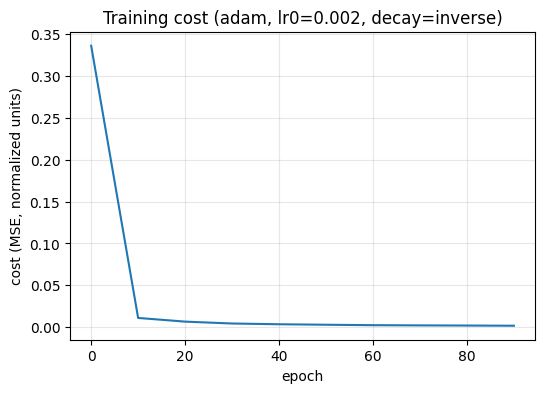

In [14]:
VERSION = "v8"
NOTES = "LR decay paired with a larger alpha0 (Section 3.8/4.4): a 3-pass sweep (coarse -> fine -> even-larger alpha0) found alpha0=2e-3 decaying to ~3e-4 by epoch 99 as the best config, beating v6/v7's tuned-fixed-alpha baseline (31.61mm) by 29%. Full sweep grid and analysis in thesis_doc.md Sec 4.4."

layer_dims = [4, 256, 128, 64, 4]  # input (x,y,z,elbow_config) -> hidden -> hidden -> output (sin_theta1, cos_theta1, theta2, theta3)
BATCH_SIZE = 256  # v5: mini-batch GD (Section 3.6/3.8); set to None to reproduce the v0-v4 full-batch baseline
NUM_ITERATIONS = 100  # epochs, since BATCH_SIZE is set

OPTIMIZER = "adam"  # v6: "adam" (Section 3.7) or "gd" to reproduce v0-v5
BETA1, BETA2, EPSILON = 0.9, 0.999, 1e-8

# v8 (Section 4.4): alpha0=2e-3, NOT v6's 3e-4 -- decay is what makes this alpha0
# viable (fixed at 2e-3 for the whole run it's worse than v6, see thesis_doc.md
# Sec 4.4's fine-grid table). The pairing with decay below is what wins.
LEARNING_RATE = 2e-3

# v8 winning decay config: inverse decay from alpha0=2e-3 to ~3e-4 by epoch 99.
# decay_rate solves alpha0/(1+decay_rate*99) = 3e-4 -- i.e. "start fast, finish
# near the value that won v6's fixed-alpha sweep." This target (~3e-4) was
# itself confirmed as the right one to aim for: decaying further (to ~1e-4)
# was uniformly worse at the same alpha0 (thesis_doc.md Sec 4.4, Grid B).
DECAY = "inverse"
DECAY_RATE = 0.0572
TIME_INTERVAL = 10

parameters, costs, train_time, final_cost = nn_model(
    X_train_norm, Y_train_norm,
    layer_dims=layer_dims,
    learning_rate=LEARNING_RATE,
    num_iterations=NUM_ITERATIONS,
    print_every=10,
    batch_size=BATCH_SIZE,
    optimizer=OPTIMIZER,
    beta1=BETA1, beta2=BETA2, epsilon=EPSILON,
    decay=DECAY, decay_rate=DECAY_RATE, time_interval=TIME_INTERVAL,
)

plt.figure(figsize=(6, 4))
plt.plot(np.arange(len(costs)) * 10, costs)
plt.xlabel("epoch" if BATCH_SIZE is not None else "iteration")
plt.ylabel("cost (MSE, normalized units)")
plt.title(f"Training cost ({OPTIMIZER}, lr0={LEARNING_RATE:g}, decay={DECAY})")
plt.grid(alpha=0.3)
plt.show()

In [15]:
## ---- Inference: caller only supplies (x,y,z); resolve elbow_config internally ----
def predict_ik(xyz_raw, parameters):
    """xyz_raw: (3, m) raw (unnormalized) target end-effector positions.

    The network was trained with elbow_config as an oracle input, so at
    inference we don't know it -- instead we query the network with BOTH
    elbow_config = +1 and -1, decode each candidate to a theta triple, run
    it back through forward kinematics, and keep whichever candidate's
    reprojected position is closer to the requested xyz_raw. This is what
    resolves the elbow ambiguity without the caller ever supplying it.

    Returns: pred_theta (3, m), chosen_elbow_config (m,), pose_err_mm (m,)
    -- the achieved FK-reprojection error of whichever candidate was picked.
    """
    m = xyz_raw.shape[1]
    candidates = {}
    for config in (1.0, -1.0):
        config_row = np.full((1, m), config)
        X_query = np.vstack([xyz_raw, config_row])
        X_query_norm = normalize(X_query, X_mean, X_std)

        AL_norm, _ = forward_propagation(X_query_norm, parameters)
        pred_enc = denormalize(AL_norm, Y_mean, Y_std)
        pred_theta = decode_theta1_sincos(pred_enc)
        pose_err = pose_error_mm(pred_theta, xyz_raw)

        candidates[config] = (pred_theta, pose_err)

    theta_pos, err_pos = candidates[1.0]
    theta_neg, err_neg = candidates[-1.0]

    use_pos = err_pos <= err_neg  # (m,)
    pred_theta = np.where(use_pos[None, :], theta_pos, theta_neg)
    chosen_elbow_config = np.where(use_pos, 1.0, -1.0)
    pose_err = np.minimum(err_pos, err_neg)

    return pred_theta, chosen_elbow_config, pose_err


## ---- Evaluate on dev + test sets ----
def evaluate(xyz_raw, Y_true_raw, parameters, split_name):
    pred_theta, chosen_elbow_config, pose_err = predict_ik(xyz_raw, parameters)

    true_elbow_config = encode_elbow_config(Y_true_raw)[0]
    config_accuracy = np.mean(chosen_elbow_config == true_elbow_config)

    joint_mae = mae_degrees(pred_theta, Y_true_raw)
    mean_angle_mae = joint_mae.mean()

    print(f"--- {split_name} ---")
    print(f"theta1 MAE: {joint_mae[0]:.3f} deg   theta2 MAE: {joint_mae[1]:.3f} deg   theta3 MAE: {joint_mae[2]:.3f} deg")
    print(f"mean angle MAE: {mean_angle_mae:.3f} deg")
    print(f"elbow-config selection accuracy (best-of-2 vs. true branch): {config_accuracy:.1%}")
    print(f"pose error: mean {pose_err.mean():.2f} mm   median {np.median(pose_err):.2f} mm   p95 {np.percentile(pose_err, 95):.2f} mm")
    print()

    return pred_theta, joint_mae, pose_err, config_accuracy


dev_pred_theta, dev_joint_mae, dev_pose_err, dev_config_acc = evaluate(X_dev_xyz, Y_dev_raw, parameters, "dev")
test_pred_theta, test_joint_mae, test_pose_err, test_config_acc = evaluate(X_test_xyz, Y_test_raw, parameters, "test")


## ---- Structured run log: append this run's config + metrics as one CSV row ----
def log_run_metrics(
    log_path, version, notes, layer_dims, learning_rate, batch_size, num_iterations,
    train_time_sec, final_cost, N_samples,
    dev_joint_mae, dev_pose_err, dev_config_acc,
    test_joint_mae, test_pose_err, test_config_acc,
    optimizer="gd", beta1=None, beta2=None, epsilon=None,
    decay=None, decay_rate=None, time_interval=None,
):
    """Appends one row per training run to a CSV log (creates it with a header on first use).

    Turns version-to-version comparison into reading a file instead of
    re-transcribing numbers from printed output into thesis_doc.md by hand.

    If the field list has changed since the file was written (v7 added the
    decay columns), the old file is archived rather than appended to --
    appending under a changed header would silently misalign every column.
    """
    import csv
    import os
    from datetime import datetime

    fieldnames = [
        "version", "timestamp", "notes", "layer_dims", "optimizer", "learning_rate", "batch_size",
        "num_iterations", "beta1", "beta2", "epsilon", "decay", "decay_rate", "time_interval",
        "train_time_sec", "final_cost", "N_samples",
        "dev_theta1_mae_deg", "dev_theta2_mae_deg", "dev_theta3_mae_deg", "dev_mean_angle_mae_deg",
        "dev_elbow_selection_acc", "dev_pose_err_mean_mm", "dev_pose_err_median_mm", "dev_pose_err_p95_mm",
        "test_theta1_mae_deg", "test_theta2_mae_deg", "test_theta3_mae_deg", "test_mean_angle_mae_deg",
        "test_elbow_selection_acc", "test_pose_err_mean_mm", "test_pose_err_median_mm", "test_pose_err_p95_mm",
    ]

    def _round(x, n):
        """round() that tolerates the NaN/inf a diverged run produces."""
        x = float(x)
        return round(x, n) if np.isfinite(x) else x

    row = {
        "version": version,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "notes": notes,
        "layer_dims": str(layer_dims),
        "optimizer": optimizer,
        "learning_rate": learning_rate,
        "batch_size": batch_size if batch_size is not None else "",
        "num_iterations": num_iterations,
        "beta1": beta1 if beta1 is not None else "",
        "beta2": beta2 if beta2 is not None else "",
        "epsilon": epsilon if epsilon is not None else "",
        "decay": decay if decay is not None else "",
        "decay_rate": decay_rate if decay is not None else "",
        "time_interval": time_interval if decay == "staircase" else "",
        "train_time_sec": _round(train_time_sec, 1),
        "final_cost": _round(final_cost, 6),
        "N_samples": N_samples,
        "dev_theta1_mae_deg": _round(dev_joint_mae[0], 3),
        "dev_theta2_mae_deg": _round(dev_joint_mae[1], 3),
        "dev_theta3_mae_deg": _round(dev_joint_mae[2], 3),
        "dev_mean_angle_mae_deg": _round(dev_joint_mae.mean(), 3),
        "dev_elbow_selection_acc": _round(dev_config_acc, 4),
        "dev_pose_err_mean_mm": _round(dev_pose_err.mean(), 2),
        "dev_pose_err_median_mm": _round(np.median(dev_pose_err), 2),
        "dev_pose_err_p95_mm": _round(np.percentile(dev_pose_err, 95), 2),
        "test_theta1_mae_deg": _round(test_joint_mae[0], 3),
        "test_theta2_mae_deg": _round(test_joint_mae[1], 3),
        "test_theta3_mae_deg": _round(test_joint_mae[2], 3),
        "test_mean_angle_mae_deg": _round(test_joint_mae.mean(), 3),
        "test_elbow_selection_acc": _round(test_config_acc, 4),
        "test_pose_err_mean_mm": _round(test_pose_err.mean(), 2),
        "test_pose_err_median_mm": _round(np.median(test_pose_err), 2),
        "test_pose_err_p95_mm": _round(np.percentile(test_pose_err, 95), 2),
    }

    file_exists = os.path.exists(log_path)
    if file_exists:
        with open(log_path, newline="") as f:
            existing_header = next(csv.reader(f), None)
        if existing_header != fieldnames:
            stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            archived = f"{os.path.splitext(log_path)[0]}_schema_{stamp}.csv"
            os.rename(log_path, archived)
            print(f"log schema changed -- archived the previous log to {archived}")
            file_exists = False

    with open(log_path, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        if not file_exists:
            writer.writeheader()
        writer.writerow(row)

    print(f"logged run '{version}' to {log_path}")


log_run_metrics(
    log_path="model_a_training_log.csv",
    version=VERSION, notes=NOTES,
    layer_dims=layer_dims, learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, num_iterations=NUM_ITERATIONS,
    optimizer=OPTIMIZER, beta1=BETA1, beta2=BETA2, epsilon=EPSILON,
    decay=DECAY, decay_rate=DECAY_RATE, time_interval=TIME_INTERVAL,
    train_time_sec=train_time, final_cost=final_cost, N_samples=N_SAMPLES,
    dev_joint_mae=dev_joint_mae, dev_pose_err=dev_pose_err, dev_config_acc=dev_config_acc,
    test_joint_mae=test_joint_mae, test_pose_err=test_pose_err, test_config_acc=test_config_acc,
)

--- dev ---
theta1 MAE: 0.474 deg   theta2 MAE: 12.222 deg   theta3 MAE: 38.077 deg
mean angle MAE: 16.925 deg
elbow-config selection accuracy (best-of-2 vs. true branch): 56.0%
pose error: mean 22.61 mm   median 20.95 mm   p95 42.75 mm

--- test ---
theta1 MAE: 0.477 deg   theta2 MAE: 11.699 deg   theta3 MAE: 36.432 deg
mean angle MAE: 16.203 deg
elbow-config selection accuracy (best-of-2 vs. true branch): 58.8%
pose error: mean 22.61 mm   median 20.91 mm   p95 43.32 mm

logged run 'v8' to model_a_training_log.csv


### 4.5 Diagnostic: oracle-conditioned evaluation (isolating regression error from branch selection)

`predict_ik`'s best-of-2 selection makes it impossible to tell, from the headline numbers alone, how much of $\theta_2$/$\theta_3$'s MAE and pose error is the *regression* being imprecise versus the *reprojection heuristic* picking the wrong (but still valid) elbow branch.

This cell re-evaluates the same trained `parameters` but feeds the network the **true** `elbow_config` at inference (an oracle only available because we're diagnosing, not deploying) instead of querying both and picking by reprojection distance. Comparing this against the best-of-2 numbers above isolates the two error sources:

- If oracle-conditioned $\theta_2$/$\theta_3$ MAE is close to $\theta_1$'s (~0.5°), the regression itself is accurate and the reported 11.7°/36.4° is mostly branch-selection noise, not a training or capacity problem.
- If oracle-conditioned MAE stays high, the regression itself hasn't converged on those joints and no amount of better branch selection would fix it.

In [16]:
## ---- Diagnostic: oracle-conditioned evaluation (isolates regression error from elbow selection) ----
def evaluate_oracle(xyz_raw, Y_true_raw, parameters, split_name):
    """Same as evaluate(), but supplies the TRUE elbow_config instead of
    best-of-2 selection. Isolates how well the regression itself has
    learned each branch, decoupled from whether predict_ik's reprojection
    heuristic picks the branch matching the sampled label.
    """
    m = xyz_raw.shape[1]
    true_elbow_config = encode_elbow_config(Y_true_raw)[0]  # (m,)
    config_row = true_elbow_config.reshape(1, m)
    X_query = np.vstack([xyz_raw, config_row])
    X_query_norm = normalize(X_query, X_mean, X_std)

    AL_norm, _ = forward_propagation(X_query_norm, parameters)
    pred_enc = denormalize(AL_norm, Y_mean, Y_std)
    pred_theta = decode_theta1_sincos(pred_enc)
    pose_err = pose_error_mm(pred_theta, xyz_raw)

    joint_mae = mae_degrees(pred_theta, Y_true_raw)
    mean_angle_mae = joint_mae.mean()

    print(f"--- {split_name} (oracle elbow_config) ---")
    print(f"theta1 MAE: {joint_mae[0]:.3f} deg   theta2 MAE: {joint_mae[1]:.3f} deg   theta3 MAE: {joint_mae[2]:.3f} deg")
    print(f"mean angle MAE: {mean_angle_mae:.3f} deg")
    print(f"pose error: mean {pose_err.mean():.2f} mm   median {np.median(pose_err):.2f} mm   p95 {np.percentile(pose_err, 95):.2f} mm")
    print()

    return pred_theta, joint_mae, pose_err


print("=" * 70)
print("ORACLE-CONDITIONED DIAGNOSTIC -- isolates regression error from")
print("elbow-branch selection. Compare against the best-of-2 numbers above.")
print("=" * 70)
print()

dev_oracle_pred, dev_oracle_mae, dev_oracle_pose = evaluate_oracle(X_dev_xyz, Y_dev_raw, parameters, "dev")
test_oracle_pred, test_oracle_mae, test_oracle_pose = evaluate_oracle(X_test_xyz, Y_test_raw, parameters, "test")

print("--- comparison: best-of-2 vs. oracle (test set) ---")
print(f"theta1 MAE:      best-of-2 {test_joint_mae[0]:.3f} deg   ->   oracle {test_oracle_mae[0]:.3f} deg")
print(f"theta2 MAE:      best-of-2 {test_joint_mae[1]:.3f} deg   ->   oracle {test_oracle_mae[1]:.3f} deg")
print(f"theta3 MAE:      best-of-2 {test_joint_mae[2]:.3f} deg   ->   oracle {test_oracle_mae[2]:.3f} deg")
print(f"mean angle MAE:  best-of-2 {test_joint_mae.mean():.3f} deg   ->   oracle {test_oracle_mae.mean():.3f} deg")
print(f"pose error mean: best-of-2 {test_pose_err.mean():.2f} mm   ->   oracle {test_oracle_pose.mean():.2f} mm")

ORACLE-CONDITIONED DIAGNOSTIC -- isolates regression error from
elbow-branch selection. Compare against the best-of-2 numbers above.

--- dev (oracle elbow_config) ---
theta1 MAE: 0.665 deg   theta2 MAE: 0.951 deg   theta3 MAE: 1.922 deg
mean angle MAE: 1.179 deg
pose error: mean 30.72 mm   median 28.03 mm   p95 61.91 mm

--- test (oracle elbow_config) ---
theta1 MAE: 0.652 deg   theta2 MAE: 0.941 deg   theta3 MAE: 1.974 deg
mean angle MAE: 1.189 deg
pose error: mean 30.16 mm   median 27.65 mm   p95 62.19 mm

--- comparison: best-of-2 vs. oracle (test set) ---
theta1 MAE:      best-of-2 0.477 deg   ->   oracle 0.652 deg
theta2 MAE:      best-of-2 11.699 deg   ->   oracle 0.941 deg
theta3 MAE:      best-of-2 36.432 deg   ->   oracle 1.974 deg
mean angle MAE:  best-of-2 16.203 deg   ->   oracle 1.189 deg
pose error mean: best-of-2 22.61 mm   ->   oracle 30.16 mm


### 4.6 Diagnostic: what is the achievable ceiling for elbow-selection accuracy?

§4.5 confirmed the regression is accurate once the true elbow branch is known, but left open how much of the remaining selection error (41.2% wrong-branch rate at v8) is fixable at all. Because targets are generated by sampling joint angles uniformly and then computing FK, the *sampled* branch is always geometrically valid by construction — but the *other* branch may or may not also land within the joint limits ($\theta_2,\theta_3\in(-90°,90°)$) used at data-generation time.

If only one branch is in-limits for a given target, there is no real ambiguity and any reasonable model should resolve it correctly. If both branches are in-limits, the two solutions are equally valid IK solutions for that $(x,y,z)$, and picking the one matching the specific sampled label is close to an unresolvable coin flip — no model, however accurate its regression, can be expected to beat chance there.

This cell solves the 2-link $(r,z)$ subproblem analytically for both elbow branches (law of cosines, closed form — no network involved) and counts how many test targets fall into each case, giving a predicted accuracy ceiling: $P(\text{unique}) + 0.5 \times P(\text{ambiguous})$.

In [17]:
## ---- Diagnostic: elbow-selection accuracy ceiling (analytic, no network) ----
def elbow_branch_ceiling(xyz_raw, L1=L1, L2=L2, L3=L3,
                          theta2_lim=THETA2_LIM, theta3_lim=THETA3_LIM):
    """For each target (x,y,z), solve the 2-link (r,z) subproblem analytically
    for BOTH elbow branches (law of cosines) and count how many are within
    the joint limits used at data-generation time.

    By construction the sampled branch is always in-limits. This checks
    whether the OTHER branch is also in-limits -- if not, there is no real
    ambiguity for that target. If both are in-limits, the two solutions are
    equally valid IK solutions and picking the one matching the sampled
    label is close to a coin flip, regardless of model accuracy.

    Returns: n_unique, n_ambiguous, n_neither, ceiling (predicted best-of-2
    accuracy assuming perfect regression: 1.0 on unique targets, 0.5 on
    ambiguous ones).
    """
    x, y, z = xyz_raw[0], xyz_raw[1], xyz_raw[2]
    r = np.sqrt(x**2 + y**2) - L1
    d2 = r**2 + z**2

    cos_t3 = (d2 - L2**2 - L3**2) / (2 * L2 * L3)
    cos_t3 = np.clip(cos_t3, -1.0, 1.0)  # guard floating-point edge cases at the reach boundary

    m = xyz_raw.shape[1]
    valid_count = np.zeros(m, dtype=int)
    for sign in (+1.0, -1.0):
        theta3 = sign * np.arccos(cos_t3)
        theta2 = np.arctan2(z, r) - np.arctan2(L3 * np.sin(theta3), L2 + L3 * np.cos(theta3))
        in_limits = (
            (theta2 >= theta2_lim[0]) & (theta2 <= theta2_lim[1]) &
            (theta3 >= theta3_lim[0]) & (theta3 <= theta3_lim[1])
        )
        valid_count += in_limits.astype(int)

    n_unique = int(np.sum(valid_count == 1))
    n_ambiguous = int(np.sum(valid_count == 2))
    n_neither = int(np.sum(valid_count == 0))

    print(f"total targets: {m}")
    print(f"unique branch (only 1 valid):   {n_unique} ({n_unique/m:.1%})")
    print(f"ambiguous (both valid):         {n_ambiguous} ({n_ambiguous/m:.1%})")
    print(f"neither valid (numerical edge): {n_neither} ({n_neither/m:.1%})")

    ceiling = n_unique / m + 0.5 * n_ambiguous / m
    print(f"predicted best-of-2 accuracy ceiling (perfect regression): {ceiling:.1%}")

    return n_unique, n_ambiguous, n_neither, ceiling


print("=" * 70)
print("ELBOW-BRANCH CEILING DIAGNOSTIC -- how much of the 58.8% test")
print("selection accuracy is explained by an unresolvable coin flip?")
print("=" * 70)
print()

print("--- test set ---")
test_n_unique, test_n_ambig, test_n_neither, test_ceiling = elbow_branch_ceiling(X_test_xyz)
print()

print("--- dev set (consistency check) ---")
dev_n_unique, dev_n_ambig, dev_n_neither, dev_ceiling = elbow_branch_ceiling(X_dev_xyz)
print()

print("--- comparison ---")
print(f"observed test selection accuracy (best-of-2, v8): {test_config_acc:.1%}")
print(f"predicted ceiling (test):                          {test_ceiling:.1%}")
print(f"gap (observed - ceiling):                          {(test_config_acc - test_ceiling)*100:+.1f} pp")

ELBOW-BRANCH CEILING DIAGNOSTIC -- how much of the 58.8% test
selection accuracy is explained by an unresolvable coin flip?

--- test set ---
total targets: 3000
unique branch (only 1 valid):   476 (15.9%)
ambiguous (both valid):         2524 (84.1%)
neither valid (numerical edge): 0 (0.0%)
predicted best-of-2 accuracy ceiling (perfect regression): 57.9%

--- dev set (consistency check) ---
total targets: 3000
unique branch (only 1 valid):   475 (15.8%)
ambiguous (both valid):         2525 (84.2%)
neither valid (numerical edge): 0 (0.0%)
predicted best-of-2 accuracy ceiling (perfect regression): 57.9%

--- comparison ---
observed test selection accuracy (best-of-2, v8): 58.8%
predicted ceiling (test):                          57.9%
gap (observed - ceiling):                          +0.8 pp


### 4.2 Adam learning-rate sweep (v6)

Adam's step is magnitude-normalized, so v5's `α = 0.05` does **not** carry over — α means something different under each optimizer. Reporting "Adam beat plain GD" while also silently changing α would confound the two, which is exactly the caveat the results table already carries for v1→v2 and v3→v4.

So this cell sweeps α with **everything else pinned to v5's settings** (`[4,256,128,64,4]`, batch 256, 100 epochs, seed 1) and logs every run to `model_a_training_log.csv`. It also re-runs **plain GD at v5's own α = 0.05** as the first entry, which does double duty: it's the honest baseline row for the comparison, and it's a regression test that refactoring `nn_model`'s update into the shared `_step` helper didn't disturb the existing path (it should reproduce v5's cost of ≈ 0.012).

A diverging α is a legitimate data point, not a failed run, so the loop catches exceptions and logs non-finite results rather than losing the rest of the sweep.

**This cell deliberately does not overwrite `parameters`.** The diagnostic cells below read it, and a sweep silently reassigning it would make them describe an ambiguous run. Once a winner is known, set `LEARNING_RATE` in the training cell above and re-run it normally.

In [ ]:
## ---- v6: optimizer / learning-rate sweep (Section 4.2) ----
# Everything except (optimizer, learning_rate) is pinned to v5's settings, so
# each row differs from the v5 baseline in exactly the two things named.
SWEEP_LAYER_DIMS = [4, 256, 128, 64, 4]
SWEEP_BATCH = 256
SWEEP_EPOCHS = 100
SWEEP_SEED = 1

# (optimizer, learning_rate, version_tag)
SWEEP_CONFIGS = [
    ("gd",   0.05,  "v5-repro"),   # baseline + regression test on the _step refactor
    ("adam", 3e-4,  "v6-lr3e-04"),
    ("adam", 1e-3,  "v6-lr1e-03"),
    ("adam", 3e-3,  "v6-lr3e-03"),
    ("adam", 1e-2,  "v6-lr1e-02"),  # expected to be unstable -- kept as a data point
]

sweep_results = []

for _opt, _lr, _tag in SWEEP_CONFIGS:
    print(f"\n{'=' * 72}\n{_tag}:  optimizer={_opt}  lr={_lr:g}\n{'=' * 72}")
    try:
        _params, _costs, _time, _cost = nn_model(
            X_train_norm, Y_train_norm,
            layer_dims=SWEEP_LAYER_DIMS,
            learning_rate=_lr,
            num_iterations=SWEEP_EPOCHS,
            print_every=50,
            seed=SWEEP_SEED,
            batch_size=SWEEP_BATCH,
            optimizer=_opt,
        )
        _, _dev_mae, _dev_pose, _dev_acc = evaluate(X_dev_xyz, Y_dev_raw, _params, f"{_tag} dev")
        _, _test_mae, _test_pose, _test_acc = evaluate(X_test_xyz, Y_test_raw, _params, f"{_tag} test")

        log_run_metrics(
            log_path="model_a_training_log.csv",
            version=_tag,
            notes=f"sweep: {_opt} @ lr={_lr:g}; batch={SWEEP_BATCH}, {SWEEP_EPOCHS} epochs, all else = v5",
            layer_dims=SWEEP_LAYER_DIMS, learning_rate=_lr, batch_size=SWEEP_BATCH,
            num_iterations=SWEEP_EPOCHS,
            optimizer=_opt,
            beta1=0.9 if _opt == "adam" else None,
            beta2=0.999 if _opt == "adam" else None,
            epsilon=1e-8 if _opt == "adam" else None,
            train_time_sec=_time, final_cost=_cost, N_samples=N_SAMPLES,
            dev_joint_mae=_dev_mae, dev_pose_err=_dev_pose, dev_config_acc=_dev_acc,
            test_joint_mae=_test_mae, test_pose_err=_test_pose, test_config_acc=_test_acc,
        )
        sweep_results.append((_tag, _opt, _lr, _cost, _test_mae.mean(), _test_pose.mean(), _test_acc, _time))
    except Exception as e:
        # A diverging learning rate is informative, not a reason to abandon the sweep.
        print(f"!! {_tag} raised {type(e).__name__}: {e}")
        _nan = float("nan")
        sweep_results.append((_tag, _opt, _lr, _nan, _nan, _nan, _nan, _nan))


## ---- summary ----
print(f"\n{'=' * 72}")
print("SWEEP SUMMARY  (v5 reference: cost 0.012, angle MAE 17.18 deg, pose 48.89 mm)")
print(f"{'=' * 72}")
print(f"{'run':<12} {'opt':<5} {'lr':>8} {'cost':>11} {'angle MAE':>10} {'pose mm':>9} {'elbow':>7} {'sec':>7}")
for _tag, _opt, _lr, _cost, _mae, _pose, _acc, _time in sorted(
        sweep_results, key=lambda r: (not np.isfinite(r[5]), r[5])):
    print(f"{_tag:<12} {_opt:<5} {_lr:>8.0e} {_cost:>11.6f} {_mae:>10.3f} {_pose:>9.2f} {_acc:>6.1%} {_time:>7.1f}")

_finite = [r for r in sweep_results if np.isfinite(r[5]) and r[1] == "adam"]
if _finite:
    _best = min(_finite, key=lambda r: r[5])
    print(f"\nbest Adam run by test pose error: {_best[0]}  (lr={_best[2]:g}, {_best[5]:.2f} mm)")
    print("-> set LEARNING_RATE in the training cell above to this value and re-run it,")
    print("   so the diagnostic cells below describe one unambiguous run.")

print("\nREMINDER: model_a_training_log.csv lives in Colab's ephemeral /content and")
print("does NOT travel with the notebook on save. Download it before the runtime recycles.")


v5-repro:  optimizer=gd  lr=0.05
epoch     0  cost 0.654206
epoch    50  cost 0.021525
epoch   100  cost 0.011637  (final)
training time: 63.5s   optimizer=gd   parameter updates: 9400
--- v5-repro dev ---
theta1 MAE: 0.964 deg   theta2 MAE: 11.945 deg   theta3 MAE: 37.029 deg
mean angle MAE: 16.646 deg
elbow-config selection accuracy (best-of-2 vs. true branch): 58.1%
pose error: mean 48.98 mm   median 46.41 mm   p95 89.80 mm

--- v5-repro test ---
theta1 MAE: 0.966 deg   theta2 MAE: 12.329 deg   theta3 MAE: 38.240 deg
mean angle MAE: 17.178 deg
elbow-config selection accuracy (best-of-2 vs. true branch): 57.0%
pose error: mean 48.89 mm   median 46.29 mm   p95 88.95 mm

logged run 'v5-repro' to model_a_training_log.csv

v6-lr3e-04:  optimizer=adam  lr=0.0003
epoch     0  cost 0.675185
epoch    50  cost 0.007283
epoch   100  cost 0.003168  (final)
training time: 72.7s   optimizer=adam   parameter updates: 9400
--- v6-lr3e-04 dev ---
theta1 MAE: 0.642 deg   theta2 MAE: 11.958 deg   the

### 4.3 Learning-rate decay sweep (v7)

`α₀` is pinned to `3e-4` (v6's winner from the §4.2 sweep) throughout, so this sweep changes exactly one thing at a time versus v6: the decay schedule and its `decay_rate`. Architecture, batch size, epoch count, and seed are all held at v6's values.

`v6-repro` is both the sweep's baseline row and a second regression test on the same `_step`/decay refactor already verified above — if it doesn't reproduce v6's numbers (cost 0.003168, pose 31.61mm, angle MAE 16.485°, selection 57.0%), stop and fix that before reading any decay row.

Per §4.2's finding, ranking is by **test pose error**, not training cost — the two disagreed there and there's no reason to expect otherwise here.

In [ ]:
## ---- v7: learning-rate decay sweep (Section 4.3) ----
# alpha_0 pinned to v6's winner (3e-4); everything else pinned to v6's settings.
# Only (decay, decay_rate) vary across rows.
DECAY_SWEEP_LAYER_DIMS = [4, 256, 128, 64, 4]
DECAY_SWEEP_BATCH = 256
DECAY_SWEEP_EPOCHS = 100
DECAY_SWEEP_SEED = 1
DECAY_SWEEP_ALPHA0 = 3e-4
DECAY_SWEEP_TIME_INTERVAL = 10

# (decay, decay_rate, version_tag)
DECAY_SWEEP_CONFIGS = [
    (None,        0.0,  "v6-repro"),      # baseline + regression test on the decay hook
    ("inverse",   0.01, "v7-inv-0.01"),
    ("inverse",   0.03, "v7-inv-0.03"),
    ("inverse",   0.1,  "v7-inv-0.1"),
    ("inverse",   0.3,  "v7-inv-0.3"),
    ("staircase", 0.1,  "v7-stair-0.1"),
    ("staircase", 0.3,  "v7-stair-0.3"),
    ("staircase", 1.0,  "v7-stair-1.0"),
]

decay_sweep_results = []

for _decay, _decay_rate, _tag in DECAY_SWEEP_CONFIGS:
    print(f"\n{'=' * 72}\n{_tag}:  decay={_decay}  decay_rate={_decay_rate:g}\n{'=' * 72}")
    try:
        _params, _costs, _time, _cost = nn_model(
            X_train_norm, Y_train_norm,
            layer_dims=DECAY_SWEEP_LAYER_DIMS,
            learning_rate=DECAY_SWEEP_ALPHA0,
            num_iterations=DECAY_SWEEP_EPOCHS,
            print_every=50,
            seed=DECAY_SWEEP_SEED,
            batch_size=DECAY_SWEEP_BATCH,
            optimizer="adam",
            decay=_decay, decay_rate=_decay_rate, time_interval=DECAY_SWEEP_TIME_INTERVAL,
        )
        _, _dev_mae, _dev_pose, _dev_acc = evaluate(X_dev_xyz, Y_dev_raw, _params, f"{_tag} dev")
        _, _test_mae, _test_pose, _test_acc = evaluate(X_test_xyz, Y_test_raw, _params, f"{_tag} test")

        log_run_metrics(
            log_path="model_a_training_log.csv",
            version=_tag,
            notes=f"decay sweep: decay={_decay}, decay_rate={_decay_rate:g}; alpha0={DECAY_SWEEP_ALPHA0:g}, "
                  f"batch={DECAY_SWEEP_BATCH}, {DECAY_SWEEP_EPOCHS} epochs, all else = v6",
            layer_dims=DECAY_SWEEP_LAYER_DIMS, learning_rate=DECAY_SWEEP_ALPHA0, batch_size=DECAY_SWEEP_BATCH,
            num_iterations=DECAY_SWEEP_EPOCHS,
            optimizer="adam", beta1=0.9, beta2=0.999, epsilon=1e-8,
            decay=_decay, decay_rate=_decay_rate, time_interval=DECAY_SWEEP_TIME_INTERVAL if _decay == "staircase" else None,
            train_time_sec=_time, final_cost=_cost, N_samples=N_SAMPLES,
            dev_joint_mae=_dev_mae, dev_pose_err=_dev_pose, dev_config_acc=_dev_acc,
            test_joint_mae=_test_mae, test_pose_err=_test_pose, test_config_acc=_test_acc,
        )
        decay_sweep_results.append((_tag, _decay, _decay_rate, _cost, _test_mae.mean(), _test_pose.mean(), _test_acc, _time))
    except Exception as e:
        print(f"!! {_tag} raised {type(e).__name__}: {e}")
        _nan = float("nan")
        decay_sweep_results.append((_tag, _decay, _decay_rate, _nan, _nan, _nan, _nan, _nan))


## ---- summary ----
print(f"\n{'=' * 72}")
print("DECAY SWEEP SUMMARY  (v6 reference: cost 0.003168, angle MAE 16.485 deg, pose 31.61 mm)")
print(f"{'=' * 72}")
print(f"{'run':<14} {'decay':<10} {'rate':>6} {'cost':>11} {'angle MAE':>10} {'pose mm':>9} {'elbow':>7} {'sec':>7}")
for _tag, _decay, _rate, _cost, _mae, _pose, _acc, _time in sorted(
        decay_sweep_results, key=lambda r: (not np.isfinite(r[5]), r[5])):
    _decay_label = _decay if _decay is not None else "none"
    print(f"{_tag:<14} {_decay_label:<10} {_rate:>6.2f} {_cost:>11.6f} {_mae:>10.3f} {_pose:>9.2f} {_acc:>6.1%} {_time:>7.1f}")

_finite = [r for r in decay_sweep_results if np.isfinite(r[5])]
if _finite:
    _best = min(_finite, key=lambda r: r[5])
    print(f"\nbest run by test pose error: {_best[0]}  ({_best[5]:.2f} mm)")
    print("-> set DECAY/DECAY_RATE/TIME_INTERVAL in the training cell above to this value and re-run it,")
    print("   so the diagnostic cells below describe one unambiguous run.")

print("\nREMINDER: model_a_training_log.csv lives in Colab's ephemeral /content and")
print("does NOT travel with the notebook on save. Download it before the runtime recycles.")


v6-repro:  decay=None  decay_rate=0
epoch     0  cost 0.675185  lr 0.0003
epoch    50  cost 0.007283  lr 0.0003
epoch   100  cost 0.003168  (final)
training time: 59.8s   optimizer=adam   parameter updates: 9400   lr: 0.0003 -> 0.0003
--- v6-repro dev ---
theta1 MAE: 0.642 deg   theta2 MAE: 11.958 deg   theta3 MAE: 37.376 deg
mean angle MAE: 16.659 deg
elbow-config selection accuracy (best-of-2 vs. true branch): 57.1%
pose error: mean 31.80 mm   median 29.33 mm   p95 60.78 mm

--- v6-repro test ---
theta1 MAE: 0.644 deg   theta2 MAE: 11.861 deg   theta3 MAE: 36.949 deg
mean angle MAE: 16.485 deg
elbow-config selection accuracy (best-of-2 vs. true branch): 57.0%
pose error: mean 31.61 mm   median 28.84 mm   p95 60.09 mm

logged run 'v6-repro' to model_a_training_log.csv

v7-inv-0.01:  decay=inverse  decay_rate=0.01
epoch     0  cost 0.675185  lr 0.0003
epoch    50  cost 0.007877  lr 0.0002
epoch   100  cost 0.003870  (final)
training time: 62.5s   optimizer=adam   parameter updates: 94

## 5. Diagnostic: is the remaining pose error singularity-driven or a general precision ceiling?

v3's mean test pose error (101.64mm) is much better than v2's (193.88mm), but still far from the thesis requirement. Before deciding whether to address singularities (oversample near `theta3≈0` / `r≈0`) or just train harder (Adam, more iterations, more capacity), check where the remaining error actually concentrates:

- Correlate pose error with `|sin(theta3)|` (elbow-singularity proximity — smaller means closer to full extension) and with `r` (base-singularity proximity — smaller means closer to the folded/degenerate configuration).
- Compare the worst-error decile's average proximity to each singularity against the overall average.
- Check whether best-of-2 branch-selection accuracy itself degrades near either singularity (plausible: the two branches may become harder to tell apart there).

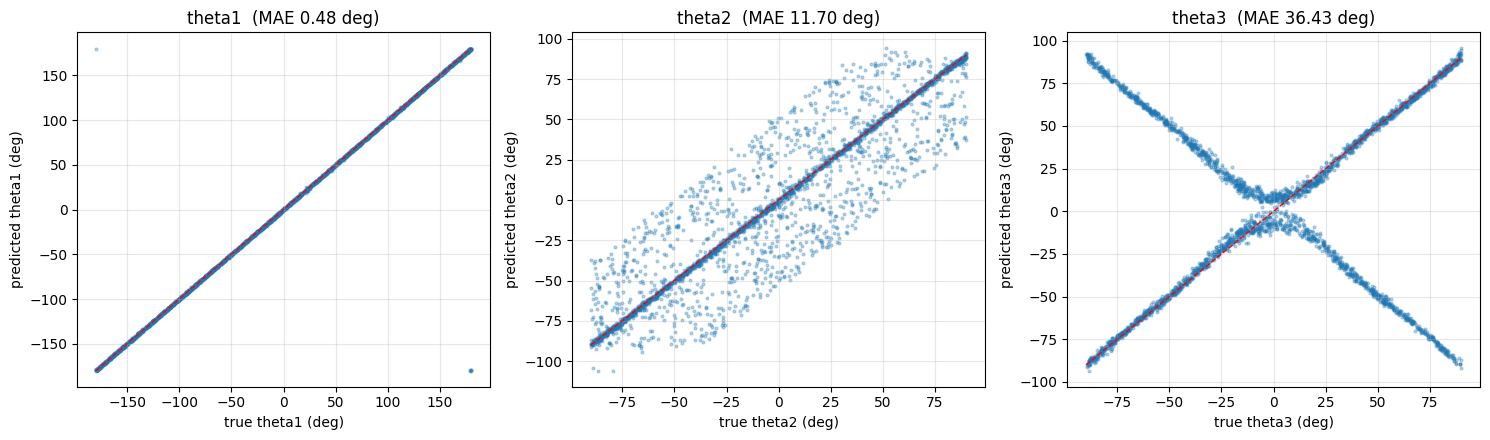

In [ ]:
## ---- Predicted vs. true, per joint (test set) ----
# Note: theta1's scatter can show points near opposite plot corners (e.g. true
# ~+179 deg vs predicted ~-179 deg) even for an accurate model -- that's a
# plotting artifact of the +-180 deg wrap, not an error (mae_degrees above
# already accounts for it via circular distance).
joint_names = ["theta1", "theta2", "theta3"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, ax in enumerate(axes):
    true_deg = np.degrees(Y_test_raw[i])
    pred_deg = np.degrees(test_pred_theta[i])
    ax.scatter(true_deg, pred_deg, s=4, alpha=0.3)
    lo, hi = true_deg.min(), true_deg.max()
    ax.plot([lo, hi], [lo, hi], "r--", linewidth=1)
    ax.set_xlabel(f"true {joint_names[i]} (deg)")
    ax.set_ylabel(f"predicted {joint_names[i]} (deg)")
    ax.set_title(f"{joint_names[i]}  (MAE {test_joint_mae[i]:.2f} deg)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
## ---- Singularity proximity proxies (test set) ----
theta3_true = Y_test_raw[2]
r_true = np.sqrt(X_test_xyz[0] ** 2 + X_test_xyz[1] ** 2)

elbow_proxy = np.abs(np.sin(theta3_true))  # -> 0 near elbow singularity (theta3 -> 0)
base_proxy = r_true                        # -> 0 near base singularity

corr_elbow = np.corrcoef(test_pose_err, elbow_proxy)[0, 1]
corr_base = np.corrcoef(test_pose_err, base_proxy)[0, 1]

print(f"corr(pose_err, |sin(theta3)|)  [elbow singularity proxy]: {corr_elbow:.3f}")
print(f"corr(pose_err, r)              [base singularity proxy]:  {corr_base:.3f}")
print("(negative correlation = error grows as the proxy shrinks, i.e. error grows near that singularity)")

# ---- Worst-error decile vs. overall ----
worst_cut = np.percentile(test_pose_err, 90)
worst_mask = test_pose_err >= worst_cut
print(f"\nWorst decile (n={worst_mask.sum()} of {len(test_pose_err)}):")
print(f"  mean |sin(theta3)|: {elbow_proxy[worst_mask].mean():.3f}  vs overall: {elbow_proxy.mean():.3f}")
print(f"  mean r:             {base_proxy[worst_mask].mean():.3f}  vs overall: {base_proxy.mean():.3f}")

# ---- Branch-selection accuracy near each singularity ----
_, chosen_elbow_config_test, _ = predict_ik(X_test_xyz, parameters)
true_elbow_config_test = encode_elbow_config(Y_test_raw)[0]
correct_selection = chosen_elbow_config_test == true_elbow_config_test

near_elbow_sing = elbow_proxy < np.percentile(elbow_proxy, 20)
near_base_sing = base_proxy < np.percentile(base_proxy, 20)

print(f"\nSelection accuracy near elbow singularity (closest 20% to theta3=0): {correct_selection[near_elbow_sing].mean():.1%}  vs elsewhere: {correct_selection[~near_elbow_sing].mean():.1%}")
print(f"Selection accuracy near base singularity  (closest 20% to r=0):      {correct_selection[near_base_sing].mean():.1%}  vs elsewhere: {correct_selection[~near_base_sing].mean():.1%}")

print(f"\nMean pose error near elbow singularity: {test_pose_err[near_elbow_sing].mean():.2f} mm  vs elsewhere: {test_pose_err[~near_elbow_sing].mean():.2f} mm")
print(f"Mean pose error near base singularity:  {test_pose_err[near_base_sing].mean():.2f} mm  vs elsewhere: {test_pose_err[~near_base_sing].mean():.2f} mm")

corr(pose_err, |sin(theta3)|)  [elbow singularity proxy]: 0.054
corr(pose_err, r)              [base singularity proxy]:  0.059
(negative correlation = error grows as the proxy shrinks, i.e. error grows near that singularity)

Worst decile (n=300 of 3000):
  mean |sin(theta3)|: 0.666  vs overall: 0.633
  mean r:             1.908  vs overall: 1.836

Selection accuracy near elbow singularity (closest 20% to theta3=0): 57.2%  vs elsewhere: 59.2%
Selection accuracy near base singularity  (closest 20% to r=0):      85.3%  vs elsewhere: 52.1%

Mean pose error near elbow singularity: 22.71 mm  vs elsewhere: 22.59 mm
Mean pose error near base singularity:  21.37 mm  vs elsewhere: 22.92 mm
